In [2]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from scipy import stats
# from scipy.signal import stft, cwt, morlet2

pd.set_option("display.max_columns", 200)
plt.rcParams["figure.figsize"] = (12, 5)

In [3]:
# Loading the datasets
INPUT_DIR = "/kaggle/input"

# Try to auto-discover CSVs
csv_files = []
for root, _, files in os.walk(INPUT_DIR):
    for f in files:
        if f.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, f))

csv_files[:10], len(csv_files)

(['/kaggle/input/spotify-global-music-dataset-20092025/track_data_final.csv',
  '/kaggle/input/spotify-global-music-dataset-20092025/spotify_data clean.csv'],
 2)

In [4]:
# Load likely files by name
def find_csv(name_contains: str):
    matches = [p for p in csv_files if name_contains.lower() in os.path.basename(p).lower()]
    return matches[0] if matches else None

path_modern = find_csv("spotify_data_clean")   # 2025 modern
path_classic = find_csv("track_data_final")    # 2009-2023 classic

path_modern, path_classic

(None,
 '/kaggle/input/spotify-global-music-dataset-20092025/track_data_final.csv')

In [5]:
df_modern = pd.read_csv(path_modern) if path_modern else pd.DataFrame()
df_classic = pd.read_csv(path_classic) if path_classic else pd.DataFrame()

print("Modern:", df_modern.shape)
print("Classic:", df_classic.shape)
df_modern.head()

Modern: (0, 0)
Classic: (8778, 15)


""


In [6]:
# Review of the Quick Schema and Missingness
def overview(df, name):
    print(f"=== {name} ===")
    display(df.head(3))
    print(df.dtypes.value_counts())
    print("\nMissingness (top 20):")
    miss = df.isna().mean().sort_values(ascending=False).head(20)
    display(miss)

overview(df_modern, "Modern")
overview(df_classic, "Classic")

=== Modern ===


""


Series([], Name: count, dtype: int64)

Missingness (top 20):


Series([], dtype: float64)

=== Classic ===


,track_id,track_name,track_number,track_popularity,track_duration_ms,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type
0,6pymOcrCnMuCWdgGVTvUgP,3,57,61,213173,False,Britney Spears,80.0,17755451.0,['pop'],325wcm5wMnlfjmKZ8PXIIn,The Singles Collection,2009-11-09,58,compilation
1,2lWc1iJlz2NVcStV5fbtPG,Clouds,1,67,158760,False,BUNT.,69.0,293734.0,['stutter house'],2ArRQNLxf9t0O0gvmG5Vsj,Clouds,2023-01-13,1,single
2,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),11,63,225328,False,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),2021-04-09,26,album


object     8
int64      4
float64    2
bool       1
Name: count, dtype: int64

Missingness (top 20):


artist_name           0.000456
artist_popularity     0.000456
artist_followers      0.000456
artist_genres         0.000456
track_name            0.000228
album_name            0.000228
track_id              0.000000
track_number          0.000000
track_popularity      0.000000
track_duration_ms     0.000000
explicit              0.000000
album_id              0.000000
album_release_date    0.000000
album_total_tracks    0.000000
album_type            0.000000
dtype: float64

In [7]:
# Normalize Column Names and merge
def clean_cols(df):
    df = df.copy()
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
    return df

df_modern = clean_cols(df_modern)
df_classic = clean_cols(df_classic)

# Add dataset flag (useful for comparisons)
if not df_modern.empty:
    df_modern["dataset"] = "modern_2025"
if not df_classic.empty:
    df_classic["dataset"] = "classic_2009_2023"

df_all = pd.concat([df_classic, df_modern], ignore_index=True, sort=False)
print("Combined:", df_all.shape)
df_all.head()

Combined: (8778, 16)


,track_id,track_name,track_number,track_popularity,track_duration_ms,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type,dataset
0,6pymOcrCnMuCWdgGVTvUgP,3,57,61,213173,False,Britney Spears,80.0,17755451.0,['pop'],325wcm5wMnlfjmKZ8PXIIn,The Singles Collection,2009-11-09,58,compilation,classic_2009_2023
1,2lWc1iJlz2NVcStV5fbtPG,Clouds,1,67,158760,False,BUNT.,69.0,293734.0,['stutter house'],2ArRQNLxf9t0O0gvmG5Vsj,Clouds,2023-01-13,1,single,classic_2009_2023
2,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),11,63,225328,False,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),2021-04-09,26,album,classic_2009_2023
3,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,2,72,158463,True,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,2021-07-30,16,album,classic_2009_2023
4,0GLfodYacy3BJE7AI3A8en,Man Down,7,57,267013,False,Rihanna,90.0,68997177.0,[],5QG3tjE5L9F6O2vCAPph38,Loud,2010-01-01,13,album,classic_2009_2023


In [8]:
#Basic cleaning and type fixes
df = df_all.copy()

# Common fields 
possible_date_cols = [c for c in df.columns if "date" in c or "release" in c or "year" in c]
possible_date_cols

['album_release_date']

In [9]:
if "release_date" in df.columns:
    df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
elif "track_album_release_date" in df.columns:
    df["release_date"] = pd.to_datetime(df["track_album_release_date"], errors="coerce")
elif "year" in df.columns:
    # year might be int; create a date for time-series grouping
    df["release_date"] = pd.to_datetime(df["year"].astype(str) + "-01-01", errors="coerce")

# Convert explicit if present
if "explicit" in df.columns:
    # could be TRUE/FALSE strings
    df["explicit"] = df["explicit"].astype(str).str.upper().map({"TRUE": True, "FALSE": False}).fillna(False)

# Coerce popularity columns (common names)
for col in ["track_popularity", "artist_popularity", "popularity"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df.shape, df["release_date"].isna().mean() if "release_date" in df.columns else None

((8778, 16), None)

In [10]:
# Descriptive Statistics - Numeric
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
desc = df[num_cols].describe().T
desc["missing_%"] = df[num_cols].isna().mean().values * 100
desc = desc.sort_values("missing_%", ascending=False)

display(desc.head(25))


,count,mean,std,min,25%,50%,75%,max,missing_%
artist_popularity,8774.0,6.995498e+01,1.953278e+01,0.0,60.00,74.0,84.00,100.0,0.045568
artist_followers,8774.0,2.435487e+07,3.813769e+07,0.0,515276.75,6272266.5,30550549.00,145542136.0,0.045568
track_number,8778.0,5.749487e+00,6.017938e+00,1.0,1.00,4.0,9.00,102.0,0.000000
track_popularity,8778.0,5.223285e+01,2.407522e+01,0.0,39.00,58.0,71.00,100.0,0.000000
track_duration_ms,8778.0,2.101578e+05,6.332684e+04,0.0,173921.25,207276.0,239693.25,811077.0,0.000000
album_total_tracks,8778.0,1.377979e+01,1.179794e+01,1.0,6.00,13.0,17.00,181.0,0.000000


In [11]:
# Visual EDA
pop_col = "track_popularity" if "track_popularity" in df.columns else ("popularity" if "popularity" in df.columns else None)
pop_col


'track_popularity'

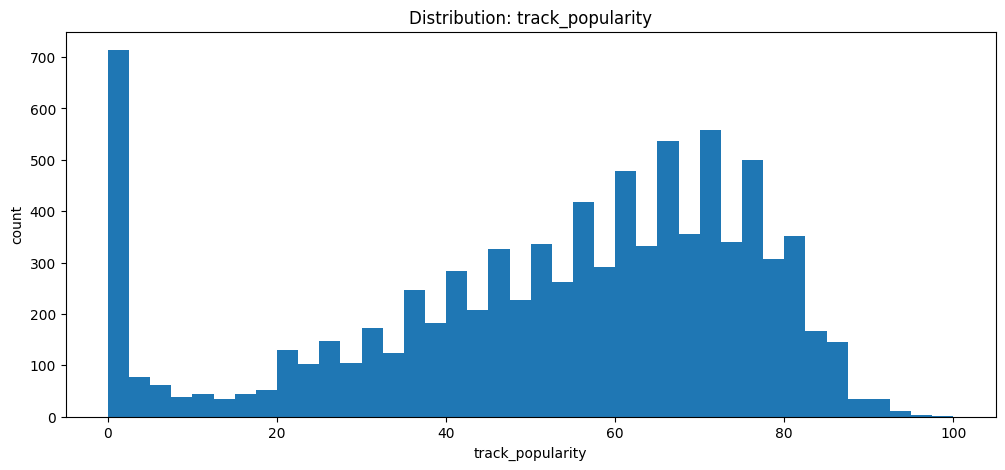

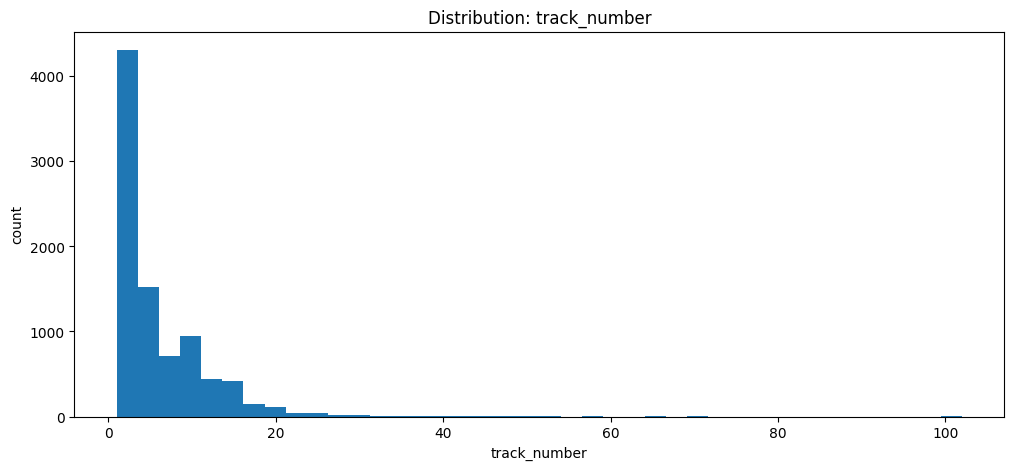

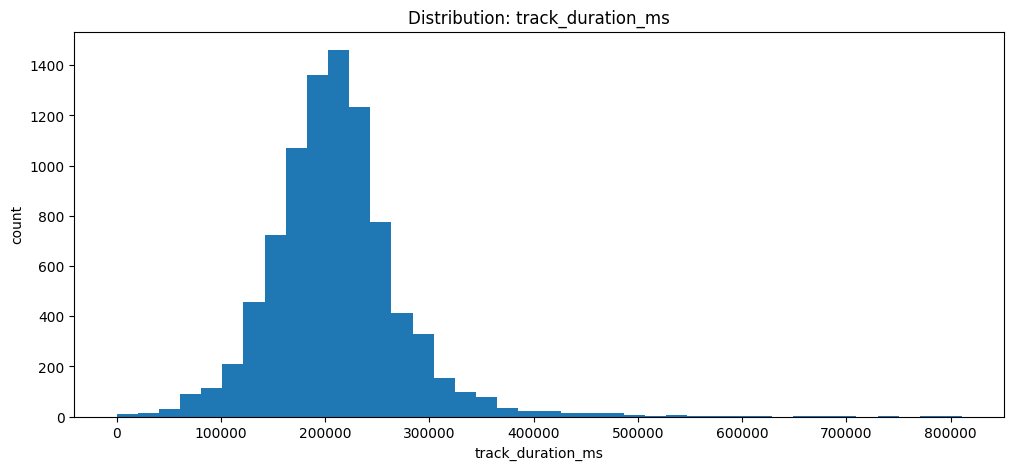

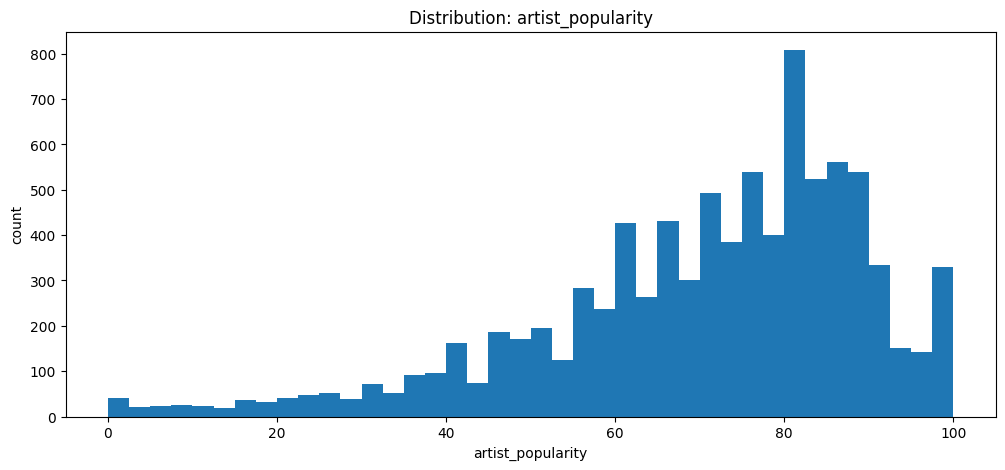

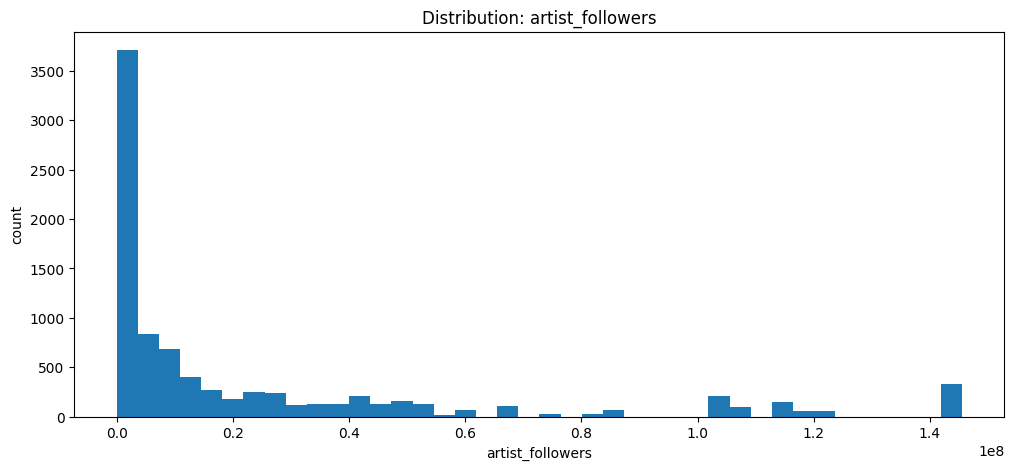

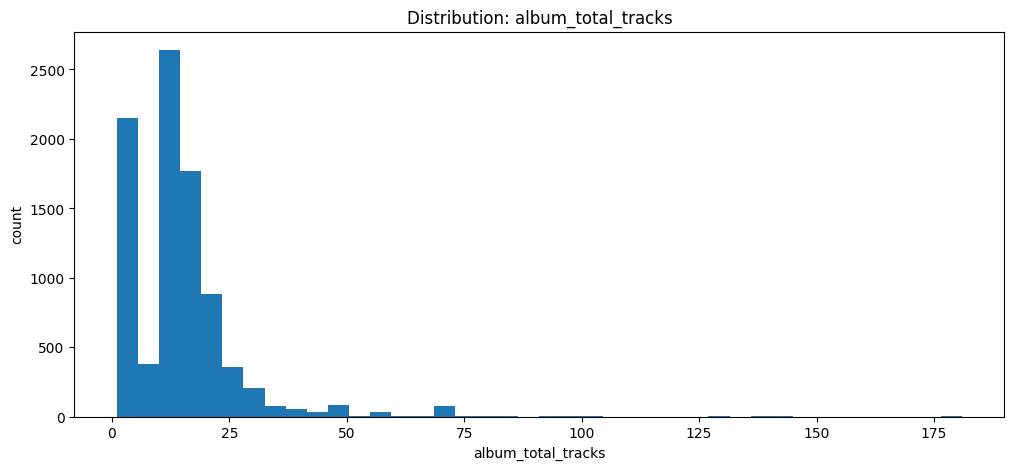

In [12]:
# Histograms for top numeric columns
plot_cols = [c for c in num_cols if c != pop_col][:6]
if pop_col:
    plot_cols = [pop_col] + plot_cols

for c in plot_cols[:8]:
    x = df[c].dropna()
    plt.figure()
    plt.hist(x, bins=40)
    plt.title(f"Distribution: {c}")
    plt.xlabel(c)
    plt.ylabel("count")
    plt.show()


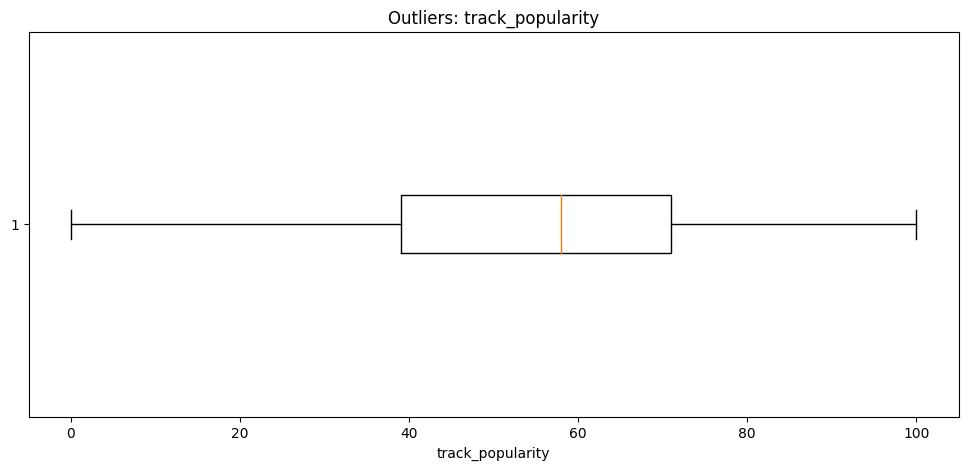

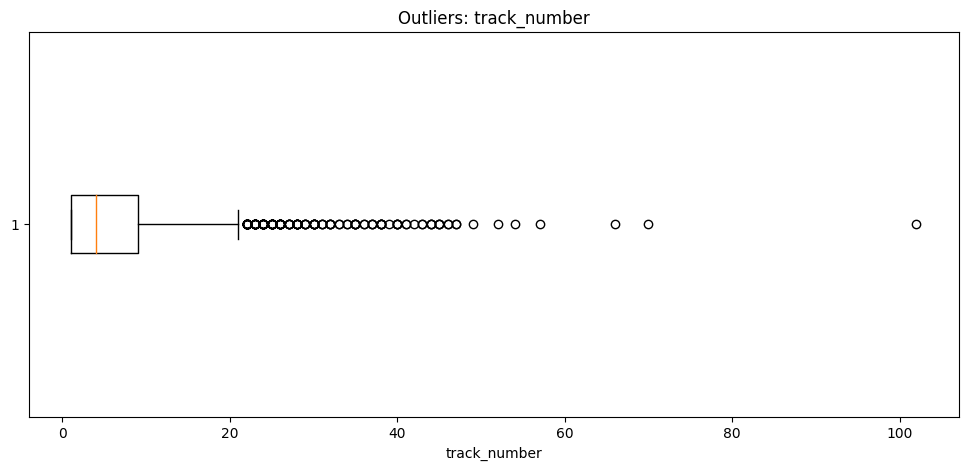

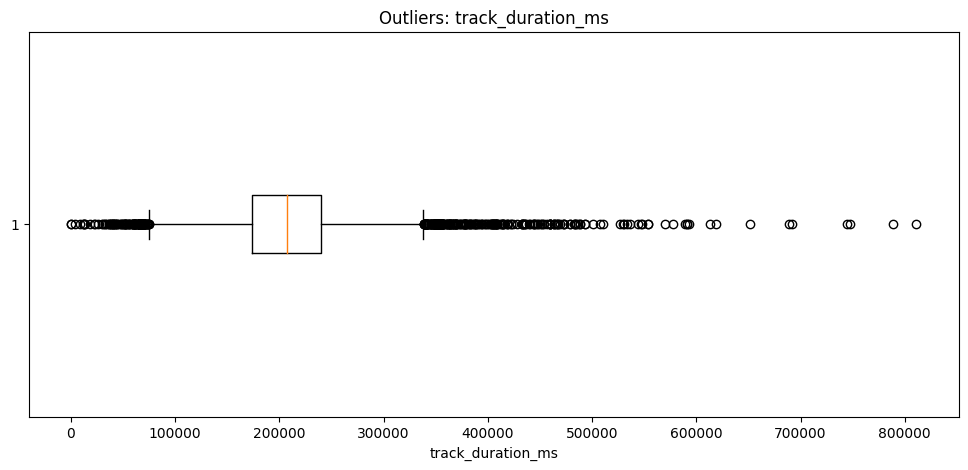

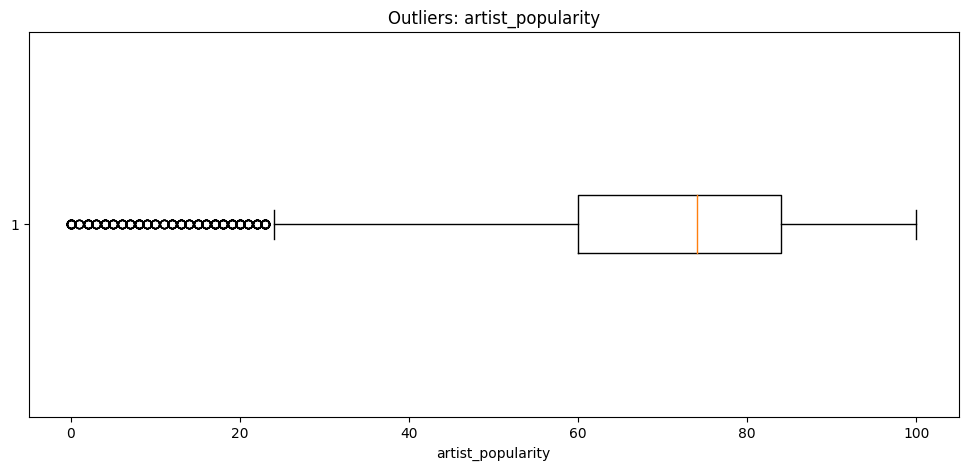

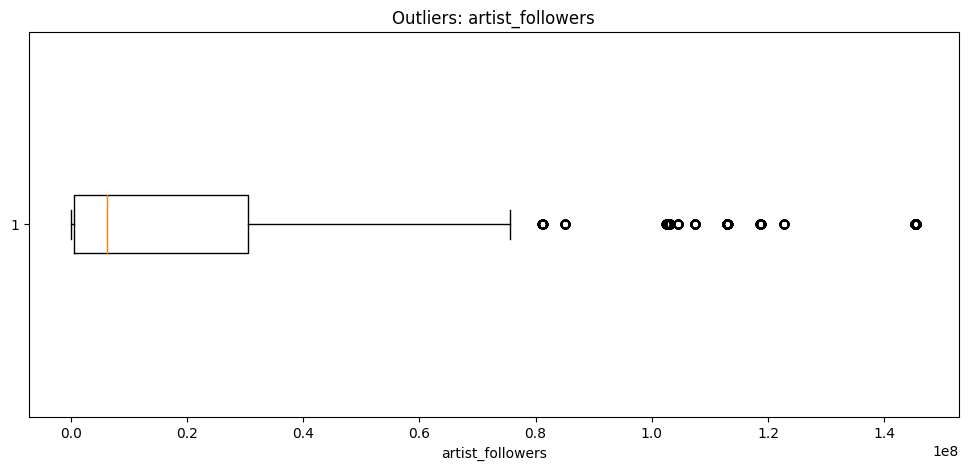

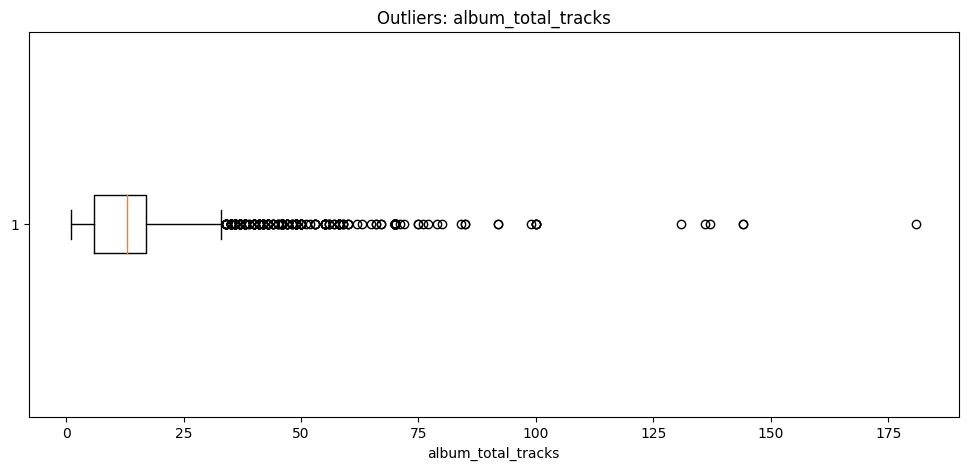

In [13]:
# Boxplots (outliers)
for c in plot_cols[:8]:
    x = df[c].dropna()
    plt.figure()
    plt.boxplot(x, vert=False)
    plt.title(f"Outliers: {c}")
    plt.xlabel(c)
    plt.show()


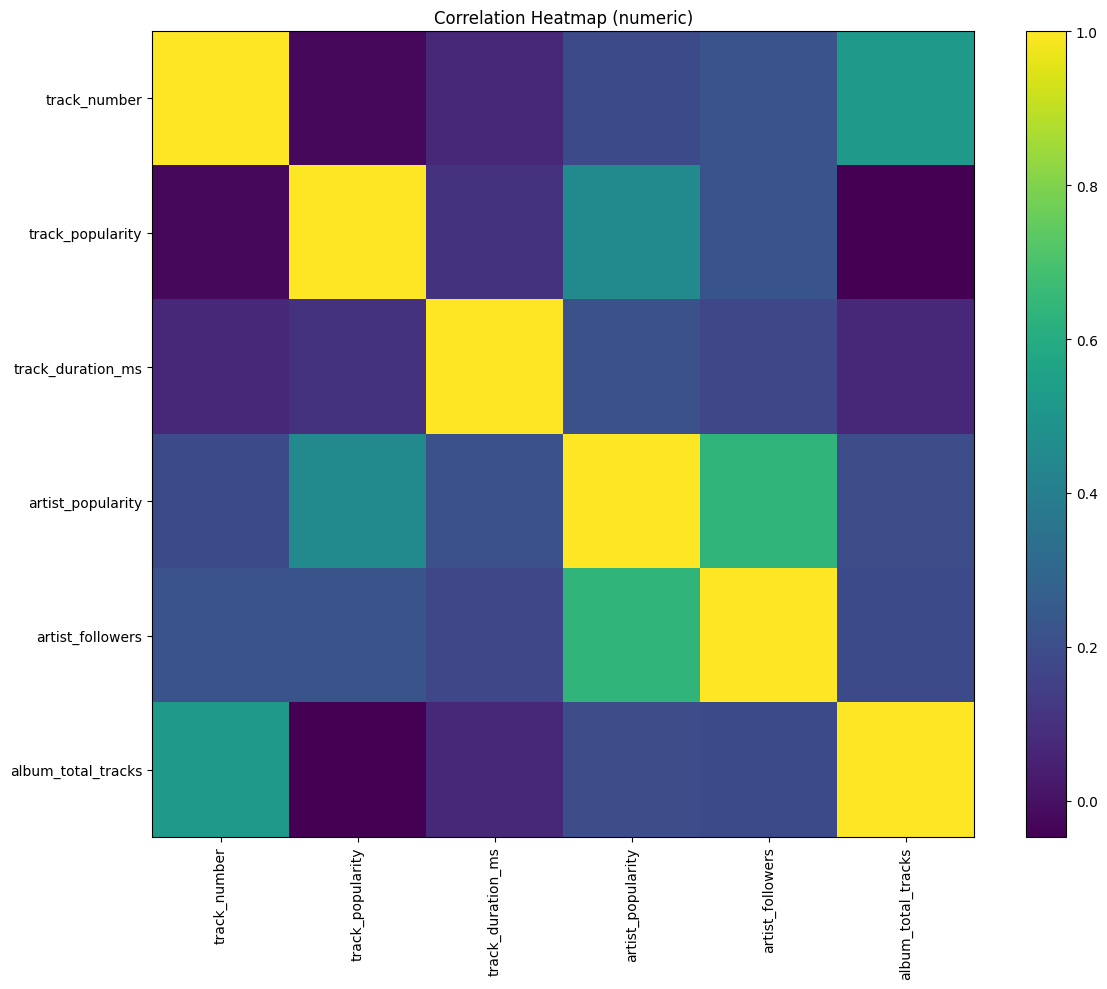

track_popularity      1.000000
artist_popularity     0.455739
artist_followers      0.226570
track_duration_ms     0.107116
album_total_tracks   -0.047275
track_number         -0.024465
Name: track_popularity, dtype: float64

In [14]:
# Correlation Heatmaps - No seaborn
# Correlation on numeric columns (drop very-missing ones)
num_use = [c for c in num_cols if df[c].isna().mean() < 0.5]
corr = df[num_use].corr(numeric_only=True)

plt.figure(figsize=(12, 10))
plt.imshow(corr, aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap (numeric)")
plt.tight_layout()
plt.show()

# Strongest correlations with popularity
if pop_col and pop_col in corr.columns:
    s = corr[pop_col].dropna().sort_values(key=lambda x: np.abs(x), ascending=False)
    display(s.head(15))


Explicit mean: 57.511861313868614 Non-explicit mean: 50.0348
Welch t-test: t = 12.591539070180344 p = 9.457612450999393e-36
Cohen's d = 0.3180467210900152


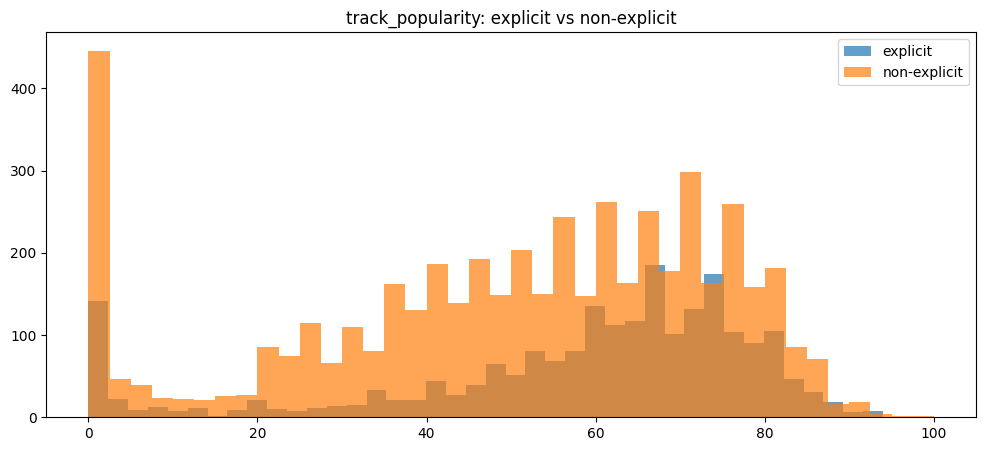

In [23]:
# Statistical Tests 
# Explicit vs Non-explicit popularity (t-test + effect size)
if pop_col and "explicit" in df.columns:
    a = df.loc[df["explicit"] == True, pop_col].dropna()
    b = df.loc[df["explicit"] == False, pop_col].dropna()
    
    # Sample if gigantic
    a_s = a.sample(min(len(a), 5000), random_state=42) if len(a) > 5000 else a
    b_s = b.sample(min(len(b), 5000), random_state=42) if len(b) > 5000 else b
    
    tstat, pval = stats.ttest_ind(a_s, b_s, equal_var=False)
    
    # Cohen's d
    d = (a_s.mean() - b_s.mean()) / np.sqrt((a_s.var(ddof=1) + b_s.var(ddof=1)) / 2)
    
    print("Explicit mean:", a_s.mean(), "Non-explicit mean:", b_s.mean())
    print("Welch t-test: t =", tstat, "p =", pval)
    print("Cohen's d =", d)

    plt.figure()
    plt.hist(a_s, bins=40, alpha=0.7, label="explicit")
    plt.hist(b_s, bins=40, alpha=0.7, label="non-explicit")
    plt.title(f"{pop_col}: explicit vs non-explicit")
    plt.legend()
    plt.show()

In [16]:
# Normality Check (Shapiro)
if pop_col:
    x = df[pop_col].dropna()
    x = x.sample(min(len(x), 5000), random_state=42) if len(x) > 5000 else x
    stat, p = stats.shapiro(x)
    print("Shapiro-Wilk stat:", stat, "p:", p)

Shapiro-Wilk stat: 0.9194275741118348 p: 1.2066612624999749e-45


In [17]:
# Build a Real “Signal” for Transforms (Time Series)
# Monthly popularity trend (mean / median / count)
if "release_date" in df.columns and pop_col:
    ts = df.dropna(subset=["release_date", pop_col]).copy()
    ts["month"] = ts["release_date"].dt.to_period("M").dt.to_timestamp()

    monthly = ts.groupby("month")[pop_col].agg(["mean", "median", "count"]).sort_index()
    display(monthly.head())

    plt.figure(figsize=(14, 5))
    plt.plot(monthly.index, monthly["mean"])
    plt.title(f"Monthly Mean {pop_col}")
    plt.xlabel("month")
    plt.ylabel("mean popularity")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(14, 5))
    plt.plot(monthly.index, monthly["count"])
    plt.title("Monthly Track Count")
    plt.xlabel("month")
    plt.ylabel("count")
    plt.tight_layout()
    plt.show()
else:
    monthly = None

In [18]:
# Fourier Transform (FFT) on Monthly Trend
if monthly is not None and len(monthly) > 24:
    y = monthly["mean"].values
    y = np.nan_to_num(y, nan=np.nanmean(y))

    # Detrend (remove linear trend) to reduce fake low-frequency dominance
    x = np.arange(len(y))
    slope, intercept, *_ = stats.linregress(x, y)
    y_detrended = y - (slope*x + intercept)

    # FFT
    Y = np.fft.rfft(y_detrended)
    freqs = np.fft.rfftfreq(len(y_detrended), d=1.0)  # d=1 month per sample

    power = np.abs(Y)**2

    plt.figure(figsize=(12, 5))
    plt.plot(freqs[1:], power[1:])  # skip DC
    plt.title("FFT Power Spectrum (Monthly Mean Popularity, detrended)")
    plt.xlabel("frequency (cycles per month)")
    plt.ylabel("power")
    plt.yscale("log")
    plt.tight_layout()
    plt.show()

    # Convert top frequencies to approximate periods (months)
    idx = np.argsort(power[1:])[::-1][:10] + 1
    top = []
    for i in idx:
        f = freqs[i]
        period = (1/f) if f > 0 else np.inf
        top.append((f, period, power[i]))
    top_df = pd.DataFrame(top, columns=["freq_cycles_per_month", "period_months", "power"])
    display(top_df)

In [19]:
# STFT (Short-Time Fourier Transform)
if monthly is not None and len(monthly) > 36:
    y = monthly["mean"].values
    y = np.nan_to_num(y, nan=np.nanmean(y))

    f, t, Z = stft(y, fs=1.0, nperseg=24, noverlap=18)  # fs=1 sample per month
    power = np.abs(Z)**2

    plt.figure(figsize=(12, 6))
    plt.imshow(power, aspect="auto", origin="lower",
               extent=[t.min(), t.max(), f.min(), f.max()])
    plt.colorbar(label="power")
    plt.title("STFT Spectrogram (Monthly Mean Popularity)")
    plt.xlabel("time (months index)")
    plt.ylabel("frequency (cycles/month)")
    plt.tight_layout()
    plt.show()

In [20]:
# Wavelet-like Transform (CWT with Morlet)
if monthly is not None and len(monthly) > 36:
    y = monthly["mean"].values
    y = np.nan_to_num(y, nan=np.nanmean(y))

    widths = np.arange(1, 49)  # scales ~ months
    cwtmatr = cwt(y, morlet2, widths, w=6)

    plt.figure(figsize=(14, 6))
    plt.imshow(np.abs(cwtmatr), aspect="auto", origin="lower",
               extent=[0, len(y), widths.min(), widths.max()])
    plt.colorbar(label="|CWT|")
    plt.title("CWT (Morlet) Scalogram of Monthly Mean Popularity")
    plt.xlabel("time (months index)")
    plt.ylabel("scale (approx months)")
    plt.tight_layout()
    plt.show()

,count,mean,median,std
dataset,,,,
classic_2009_2023,8778,52.232855,58.0,24.075221


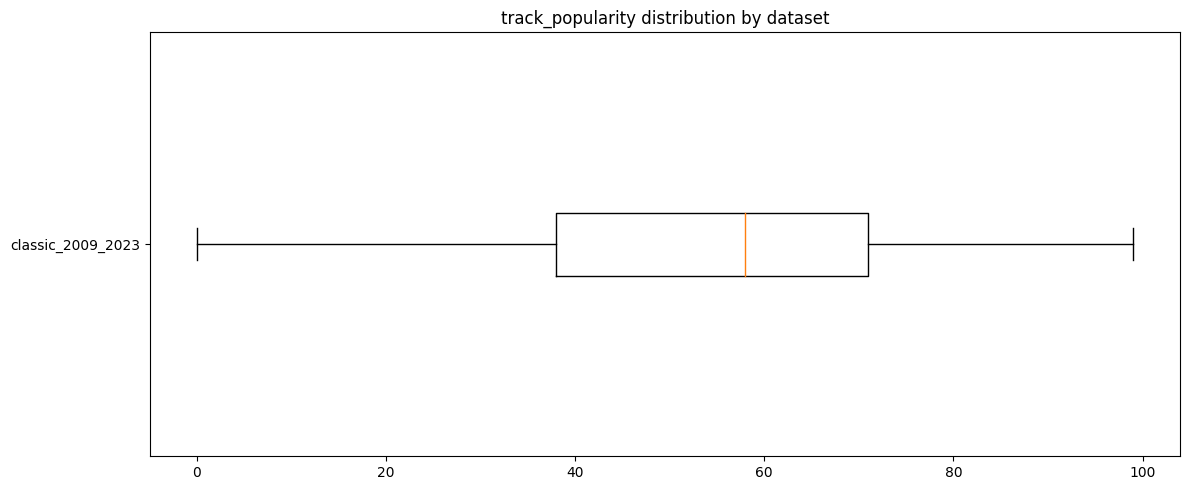

In [21]:
# “Modern vs Classic” Comparison (Trends + Distributions)
if pop_col and "dataset" in df.columns:
    grp = df.groupby("dataset")[pop_col]
    summary = grp.agg(["count", "mean", "median", "std"]).sort_values("count", ascending=False)
    display(summary)

    plt.figure()
    labels = []
    data = []
    for k, g in df.groupby("dataset"):
        x = g[pop_col].dropna()
        x = x.sample(min(len(x), 5000), random_state=42) if len(x) > 5000 else x
        labels.append(k)
        data.append(x.values)
    plt.boxplot(data, labels=labels, vert=False)
    plt.title(f"{pop_col} distribution by dataset")
    plt.tight_layout()
    plt.show()

Linear regression R^2 (sanity): 0.226071136119394


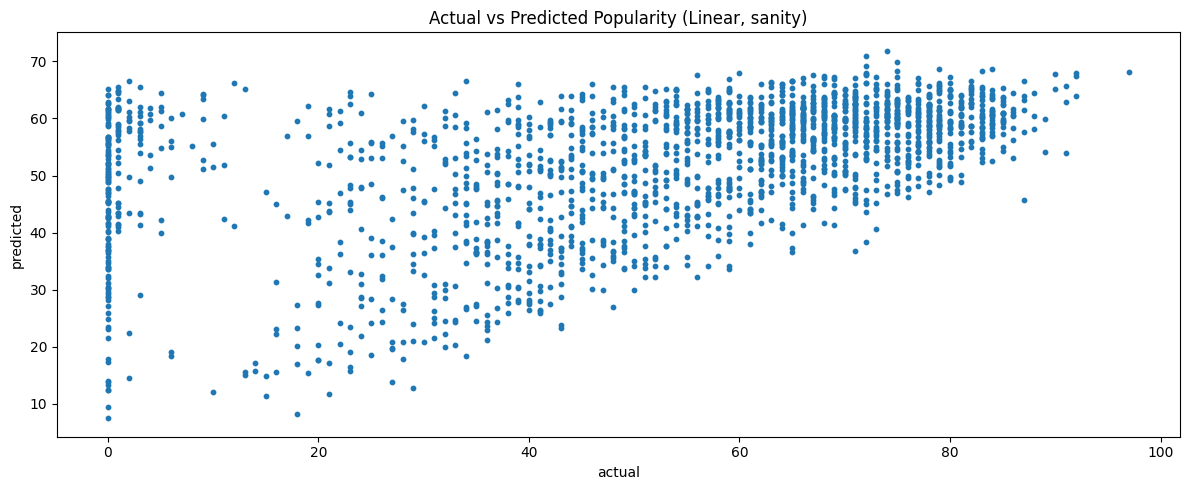

artist_popularity     12.317278
album_total_tracks    -2.689227
artist_followers      -1.312896
track_number          -1.180373
track_duration_ms      1.047299
dtype: float64

In [22]:
# Simple Predictive Check (Linear Regression sanity)
if pop_col:
    # Candidate features: numeric columns excluding IDs and popularity itself
    bad = {pop_col}
    feature_cols = [c for c in num_cols if c not in bad]
    # drop very sparse columns
    feature_cols = [c for c in feature_cols if df[c].isna().mean() < 0.2]

    model_df = df[feature_cols + [pop_col]].dropna()
    if len(model_df) > 2000:
        model_df = model_df.sample(2000, random_state=42)

    X = model_df[feature_cols].values
    y = model_df[pop_col].values

    # Standardize
    X_mean = X.mean(axis=0)
    X_std = X.std(axis=0) + 1e-9
    Xz = (X - X_mean) / X_std

    # Fit via least squares
    X_design = np.c_[np.ones(len(Xz)), Xz]
    beta, *_ = np.linalg.lstsq(X_design, y, rcond=None)
    yhat = X_design @ beta

    r2 = 1 - ((y - yhat)**2).sum() / ((y - y.mean())**2).sum()
    print("Linear regression R^2 (sanity):", r2)

    plt.figure()
    plt.scatter(y, yhat, s=10)
    plt.title("Actual vs Predicted Popularity (Linear, sanity)")
    plt.xlabel("actual")
    plt.ylabel("predicted")
    plt.tight_layout()
    plt.show()

    # Top coefficients (importance-ish)
    coefs = pd.Series(beta[1:], index=feature_cols).sort_values(key=lambda x: np.abs(x), ascending=False)
    display(coefs.head(15))